<a href="https://colab.research.google.com/github/Main72/claudeTest/blob/claude/dreamy-goldberg-iivt47/project1v2.0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projekt 1 (v2.0) — diagnostyka procesu uczenia sieci neuronowej

**Cel:** rozpoznać i ograniczyć problemy występujące podczas treningu MLP na danych „dwa półksiężyce”.

**Plan notebooka**
1. Dane: 1200 przykładów, szum 0.25, ziarno 42; stratyfikowany podział 70/15/15; skalowanie dopasowane tylko na treningu.
2. Baseline’y: klasa większościowa + regresja logistyczna → **niedouczenie**.
3. MLP (ReLU, sigmoid, BCE) bez regularyzacji → **przeuczenie** (diagnoza na dłuższym treningu).
4. Dodatkowo: zbyt duży learning rate → **niestabilny trening**.
5. Kontrolowany eksperyment: dropout `0.0 / 0.2 / 0.4` × 3 ziarna = 9 treningów (max 60 epok).
6. Wybór konfiguracji wyłącznie na walidacji → jednokrotna ocena na teście.
7. Raport końcowy.

> Uruchamiaj komórki po kolei (`Runtime → Run all`). Całość trwa ok. 5–10 minut na CPU (bez GPU).

In [1]:
# Importy i ziarna
import numpy as np  # tablice
import pandas as pd  # tabele wyników
import matplotlib.pyplot as plt  # wykresy
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import make_moons  # dane: półksiężyce
from sklearn.model_selection import train_test_split  # podział danych
from sklearn.preprocessing import StandardScaler  # standaryzacja
from sklearn.dummy import DummyClassifier  # baseline naiwny
from sklearn.linear_model import LogisticRegression  # baseline liniowy
from sklearn.metrics import accuracy_score, f1_score  # metryki

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

DATA_SEED = 42  # ziarno generatora danych (stałe)
SPLIT_SEED = 42  # ziarno podziału (stałe)
TRAIN_SEEDS = [0, 1, 2]  # ziarna inicjalizacji/treningu (3 powtórzenia)
tf.config.experimental.enable_op_determinism()  # powtarzalne operacje TF

TensorFlow: 2.21.0 | Keras: 3.15.1


## 1. Dane i podział

- `make_moons(n_samples=1200, noise=0.25, random_state=42)` → 2 cechy, etykiety 0/1.
- Podział stratyfikowany: najpierw 70% trening / 30% reszta, potem reszta 50/50 → walidacja 15% i test 15% (`random_state=42` w obu krokach).
- `StandardScaler` dopasowany **wyłącznie** na treningu; ten sam obiekt przekształca walidację (a test dopiero na samym końcu). Brak wycieku danych.

In [2]:
X, y = make_moons(n_samples=1200, noise=0.25, random_state=DATA_SEED)  # 1200 × 2

X_train, X_hold, y_train, y_hold = train_test_split(  # trening 70%
    X, y, test_size=0.30, stratify=y, random_state=SPLIT_SEED,
)
X_val, X_test, y_val, y_test = train_test_split(  # walidacja 15%; test 15%
    X_hold, y_hold, test_size=0.50, stratify=y_hold, random_state=SPLIT_SEED,
)

scaler = StandardScaler().fit(X_train)  # dopasowanie: tylko trening
X_train_s = scaler.transform(X_train).astype("float32")
X_val_s = scaler.transform(X_val).astype("float32")  # ten sam scaler
y_train_k = y_train.astype("float32").reshape(-1, 1)  # etykiety dla Keras: kolumna
y_val_k = y_val.astype("float32").reshape(-1, 1)
# X_test skalujemy dopiero w sekcji 6 (test końcowy)

split_info = pd.DataFrame({
    "zbiór": ["trening", "walidacja", "test"],
    "liczność": [len(y_train), len(y_val), len(y_test)],
    "udział klasy 1": [y_train.mean(), y_val.mean(), y_test.mean()],
})
split_info

,zbiór,liczność,udział klasy 1
0,trening,840,0.5
1,walidacja,180,0.5
2,test,180,0.5


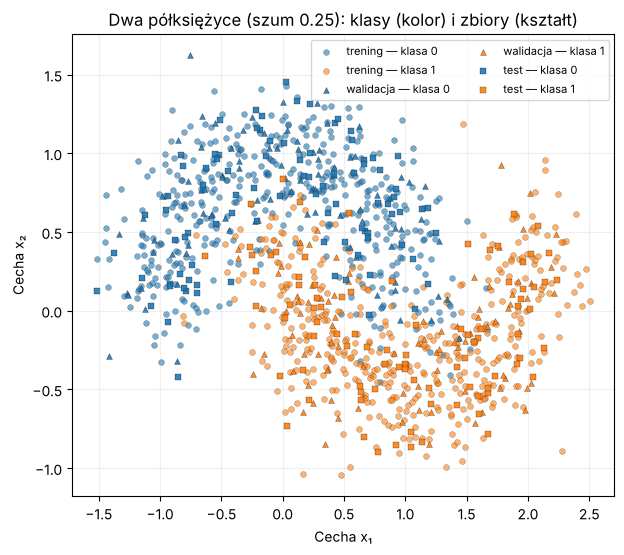

In [3]:
fig, ax = plt.subplots(figsize=(7, 6))
markers = {"trening": "o", "walidacja": "^", "test": "s"}
for name, Xs, ys in [("trening", X_train, y_train), ("walidacja", X_val, y_val), ("test", X_test, y_test)]:
    for cls, color in [(0, "tab:blue"), (1, "tab:orange")]:
        m = ys == cls
        ax.scatter(Xs[m, 0], Xs[m, 1], s=18, marker=markers[name], color=color,
                   alpha=0.6 if name == "trening" else 0.9, edgecolor="k", linewidth=0.2,
                   label=f"{name} — klasa {cls}")
ax.set(xlabel="Cecha x₁", ylabel="Cecha x₂",
       title="Dwa półksiężyce (szum 0.25): klasy (kolor) i zbiory (kształt)")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.2)
plt.show()

### Funkcje pomocnicze

- `scores` — accuracy i F1 (klasa pozytywna = 1, próg 0.5).
- `plot_boundary` — granica decyzyjna liczona na siatce w oryginalnej skali cech (siatka przekształcana tym samym `scaler`), z punktami treningu (●) i walidacji (▲). Zbiór testowy nie jest pokazywany na granicach.

In [4]:
def scores(y_true, prob):
    pred = (np.asarray(prob).ravel() >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "f1": f1_score(y_true, pred, zero_division=0)}


def bce(y_true, prob, eps=1e-7):  # binarna entropia krzyżowa (numpy)
    p = np.clip(np.asarray(prob).ravel(), eps, 1 - eps)
    return float(-np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p)))


visible = np.vstack([X_train, X_val])  # zakres siatki: trening + walidacja
gx1, gx2 = np.meshgrid(
    np.linspace(visible[:, 0].min() - 0.4, visible[:, 0].max() + 0.4, 250),
    np.linspace(visible[:, 1].min() - 0.4, visible[:, 1].max() + 0.4, 250),
)
grid_s = scaler.transform(np.column_stack([gx1.ravel(), gx2.ravel()])).astype("float32")


def plot_boundary(ax, prob_fn, title):
    prob = np.asarray(prob_fn(grid_s)).ravel().reshape(gx1.shape)
    ax.contourf(gx1, gx2, prob, levels=[0, 0.5, 1], colors=["#dce9f7", "#ffe8cc"])
    ax.contour(gx1, gx2, prob, levels=[0.5], colors="black", linewidths=1.2)
    for Xs, ys, mk, nm in [(X_train, y_train, "o", "trening"), (X_val, y_val, "^", "walidacja")]:
        for cls, color in [(0, "tab:blue"), (1, "tab:orange")]:
            m = ys == cls
            ax.scatter(Xs[m, 0], Xs[m, 1], s=14, marker=mk, color=color,
                       edgecolor="k", linewidth=0.2, label=f"{nm} — klasa {cls}")
    ax.plot([], [], color="black", label="granica p = 0.5")
    ax.set(xlabel="Cecha x₁", ylabel="Cecha x₂", title=title)
    ax.legend(fontsize=7, loc="lower left")

## 2. Baseline’y i diagnoza niedouczenia

- **Naiwny:** zawsze klasa większościowa z treningu — dolna granica, którą model musi pobić.
- **Liniowy:** regresja logistyczna — granica decyzyjna jest prostą, więc nie może odwzorować zakrzywionych półksiężyców.

**Jak rozpoznajemy niedouczenie:** wynik na treningu jest *równie słaby* jak na walidacji (mała luka, ale wysoka strata na obu zbiorach), a granica decyzyjna jest zbyt prosta względem kształtu danych. Test nie jest tu używany.

In [5]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train)
logreg = LogisticRegression().fit(X_train_s, y_train)

rows = []
for name, mdl in [("naiwny (klasa większościowa)", dummy), ("regresja logistyczna", logreg)]:
    p_tr = mdl.predict_proba(X_train_s)[:, 1]
    p_va = mdl.predict_proba(X_val_s)[:, 1]
    s_tr, s_va = scores(y_train, p_tr), scores(y_val, p_va)
    rows.append({"model": name,
                 "train BCE": bce(y_train, p_tr), "val BCE": bce(y_val, p_va),
                 "train acc": s_tr["accuracy"], "val acc": s_va["accuracy"],
                 "train F1": s_tr["f1"], "val F1": s_va["f1"]})
baseline_df = pd.DataFrame(rows).set_index("model")
baseline_df.round(3)

,train BCE,val BCE,train acc,val acc,train F1,val F1
model,,,,,,
naiwny (klasa większościowa),8.059,8.059,0.500,0.500,0.000,0.00
regresja logistyczna,0.319,0.309,0.865,0.872,0.865,0.87


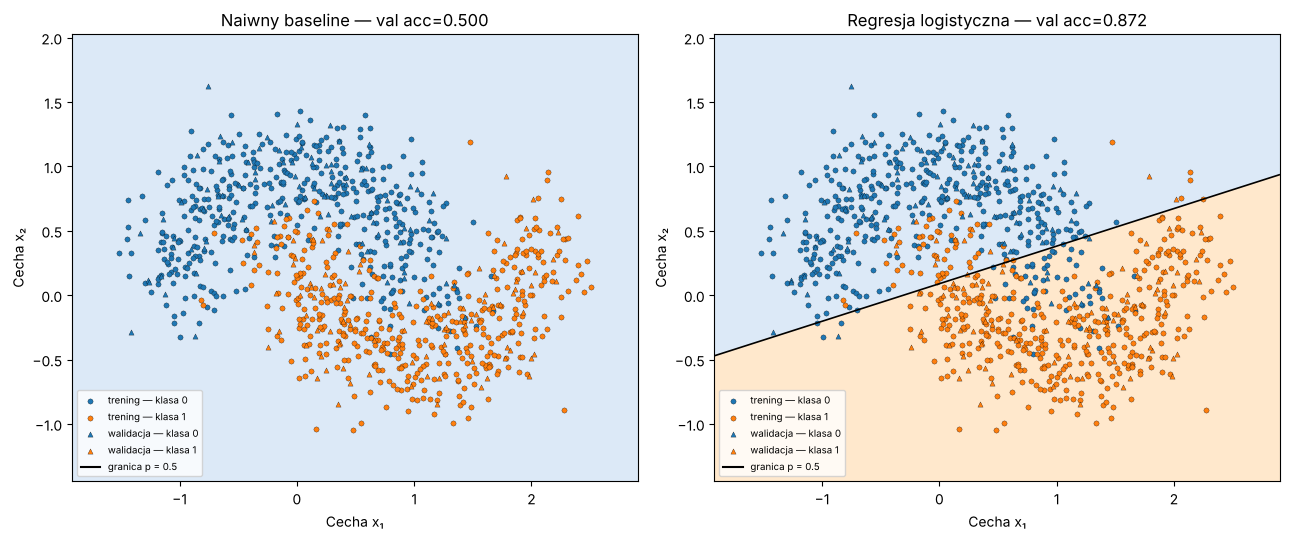

Regresja logistyczna: train acc=0.865, val acc=0.872, luka=-0.007; train BCE=0.319
→ Mała luka trening/walidacja przy wyraźnie niezerowym błędzie na TRENINGU i prostej granicy = niedouczenie (model ma za małą pojemność — tylko granica liniowa).
Uwaga: nawet tu val BCE (0.309) < train BCE (0.319) — ten zbiór walidacyjny jest nieco „łatwiejszy” niż treningowy. Dlatego przeuczenie oceniamy po WZROŚCIE luki i straty walidacyjnej w czasie, a nie po samym znaku luki.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_boundary(axes[0], lambda G: dummy.predict_proba(G)[:, 1],
              f"Naiwny baseline — val acc={baseline_df.iloc[0]['val acc']:.3f}")
plot_boundary(axes[1], lambda G: logreg.predict_proba(G)[:, 1],
              f"Regresja logistyczna — val acc={baseline_df.iloc[1]['val acc']:.3f}")
plt.tight_layout()
plt.show()

lr_row = baseline_df.loc["regresja logistyczna"]
print(f"Regresja logistyczna: train acc={lr_row['train acc']:.3f}, val acc={lr_row['val acc']:.3f}, "
      f"luka={lr_row['train acc'] - lr_row['val acc']:+.3f}; train BCE={lr_row['train BCE']:.3f}")
print("→ Mała luka trening/walidacja przy wyraźnie niezerowym błędzie na TRENINGU i prostej granicy = niedouczenie "
      "(model ma za małą pojemność — tylko granica liniowa).")
print(f"Uwaga: nawet tu val BCE ({lr_row['val BCE']:.3f}) < train BCE ({lr_row['train BCE']:.3f}) — ten zbiór walidacyjny "
      "jest nieco „łatwiejszy” niż treningowy. Dlatego przeuczenie oceniamy po WZROŚCIE luki i straty walidacyjnej "
      "w czasie, a nie po samym znaku luki.")

**Dlaczego model liniowy nie jest równoważny z MLP:** regresja logistyczna liczy `σ(w·x + b)`, więc zbiór `p = 0.5` to zawsze prosta. MLP z nieliniowymi aktywacjami ReLU składa wiele odcinkowo-liniowych fragmentów i potrafi wygiąć granicę wzdłuż półksiężyców. Naiwny baseline ma F1 = 0, bo nigdy nie przewiduje klasy 1.

## 3. MLP — ustawienia stałe w całym projekcie

| element | wartość |
|---|---|
| wejście | 2 cechy (po standaryzacji) |
| warstwy ukryte | 3 × `Dense(256, relu)`, po każdej `Dropout(p)` |
| wyjście | `Dense(1, sigmoid)` |
| strata | `binary_crossentropy` |
| optymalizator | Adam, `learning_rate = 0.003` |
| batch size | 32 |
| epoki | 60 w eksperymencie dropout (bez early stopping); 300 tylko w diagnozie przeuczenia |
| ziarna | `keras.utils.set_random_seed(seed)` ustawia Python `random`, NumPy i TensorFlow (inicjalizacja wag, maski dropout, tasowanie batchy) + `enable_op_determinism()` |

Architektura jest celowo **duża** (≈ 133 tys. parametrów na 840 przykładów treningowych) — tak, żeby bez regularyzacji model był w stanie dopasować się do szumu. Ustawienia dobrałem w próbnych uruchomieniach: przy mniejszych batchach / większym LR szum gradientu nie pozwalał modelowi „zapamiętać” danych nawet w długim treningu.

**Pomiar w każdej epoce:**
- `loss` z Keras — strata treningowa *z aktywnym dropoutem* (uśredniona po batchach),
- `train_loss_eval` — strata na całym treningu w trybie inferencji (bez dropoutu) — uczciwe porównanie z walidacją,
- `val_loss` — strata walidacyjna.

**Wybór epoki (ustalony z góry):** zapamiętujemy wagi z epoki o najmniejszym `val_loss` i to one są oceniane (accuracy/F1 na walidacji, a na końcu na teście).

In [7]:
HIDDEN = (256, 256, 256)
LEARNING_RATE = 0.003
BATCH_SIZE = 32
EPOCHS = 60  # limit w eksperymencie dropout
EPOCHS_LONG = 300  # tylko diagnoza przeuczenia (poza porównaniem)


def build_mlp(dropout, seed, learning_rate=LEARNING_RATE):
    keras.utils.set_random_seed(seed)  # Python + NumPy + TF
    layers = [keras.Input(shape=(2,))]
    for units in HIDDEN:
        layers.append(keras.layers.Dense(units, activation="relu"))
        layers.append(keras.layers.Dropout(dropout))  # 0.0 = brak dropoutu
    layers.append(keras.layers.Dense(1, activation="sigmoid"))
    model = keras.Sequential(layers)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="binary_crossentropy",
                  metrics=[keras.metrics.BinaryAccuracy(name="accuracy")])
    return model


class EpochMonitor(keras.callbacks.Callback):
    # strata treningowa bez dropoutu + wagi z epoki o minimalnym val_loss
    def on_train_begin(self, logs=None):
        self.train_loss_eval, self.best_val, self.best_epoch, self.best_weights = [], np.inf, 0, None

    def on_epoch_end(self, epoch, logs=None):
        p = self.model(X_train_s, training=False).numpy()
        self.train_loss_eval.append(bce(y_train, p))
        if logs["val_loss"] < self.best_val:
            self.best_val, self.best_epoch = logs["val_loss"], epoch + 1
            self.best_weights = self.model.get_weights()


RUNS = {}  # pamięć podręczna: (dropout, seed, lr, epoki) → wynik


def train_run(dropout, seed, learning_rate=LEARNING_RATE, epochs=EPOCHS):
    key = (dropout, seed, learning_rate, epochs)
    if key in RUNS:
        return RUNS[key]
    model = build_mlp(dropout, seed, learning_rate)
    mon = EpochMonitor()
    hist = model.fit(X_train_s, y_train_k, validation_data=(X_val_s, y_val_k),
                     epochs=epochs, batch_size=BATCH_SIZE, shuffle=True,
                     verbose=0, callbacks=[mon])
    final_tr = scores(y_train, model(X_train_s, training=False).numpy())
    final_va = scores(y_val, model(X_val_s, training=False).numpy())
    final_weights = model.get_weights()  # stan po 60 epokach
    model.set_weights(mon.best_weights)  # wagi z najlepszej epoki (wg walidacji)
    b = mon.best_epoch - 1
    gap_best = hist.history["val_loss"][b] - mon.train_loss_eval[b]
    gap_end = hist.history["val_loss"][-1] - mon.train_loss_eval[-1]
    best_tr = scores(y_train, model(X_train_s, training=False).numpy())
    best_va = scores(y_val, model(X_val_s, training=False).numpy())
    run = {
        "model": model, "dropout": dropout, "seed": seed, "lr": learning_rate,
        "loss": hist.history["loss"], "val_loss": hist.history["val_loss"],
        "train_loss_eval": mon.train_loss_eval, "best_epoch": mon.best_epoch,
        "final_weights": final_weights,
        "gap_best": gap_best, "gap_end": gap_end, "gap_growth": gap_end - gap_best,
        "final_train_acc": final_tr["accuracy"], "final_val_acc": final_va["accuracy"],
        "best_train_acc": best_tr["accuracy"], "val_acc": best_va["accuracy"], "val_f1": best_va["f1"],
    }
    RUNS[key] = run
    return run


print("Liczba parametrów MLP:", build_mlp(0.0, 0).count_params())

Liczba parametrów MLP: 132609


### 3a. Celowe przeuczenie (dropout = 0.0, brak regularyzacji)

**Jak rozpoznajemy przeuczenie:** strata treningowa dalej maleje, a strata walidacyjna po osiągnięciu minimum **rośnie** — luka val − train się powiększa. Sama wysoka accuracy na treningu nie wystarcza; patrzymy na *porównanie* trening vs walidacja w czasie.

W próbnych uruchomieniach w limicie 60 epok minimum `val_loss` wypadało dopiero pod koniec — model był na granicy przeuczenia, ale nie zdążył go wyraźnie pokazać (dane mają duży szum, a sieć ReLU na 2 cechach uczy się najpierw gładkiej granicy). Limit 60 epok dotyczy **porównania dropout**, więc do diagnozy ten sam model (to samo ziarno, te same ustawienia) trenujemy dłużej — **300 epok** — i zaznaczamy na wykresie, gdzie kończy się budżet 60 epok.

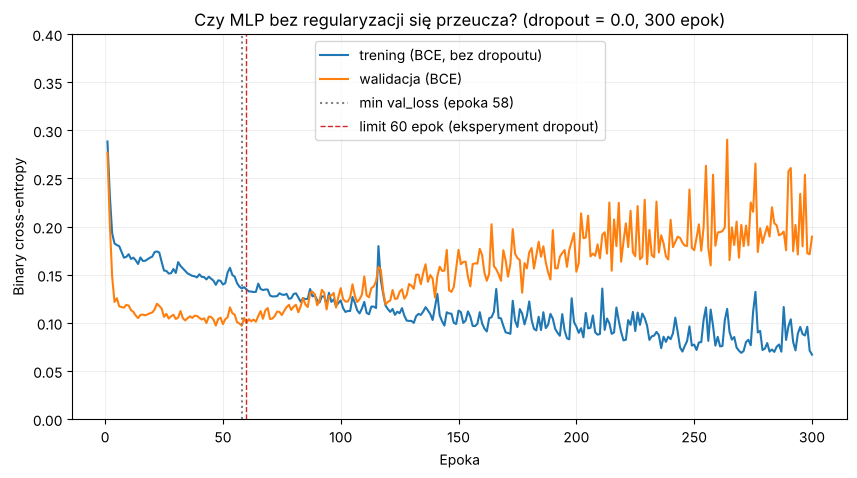

Ostatnia epoka: train BCE=0.067, val BCE=0.190
Min val BCE=0.097 w epoce 58 → do końca +0.092 (+95%)
Luka val − train: w najlepszej epoce -0.039 → na końcu +0.123 (wzrost +0.161)
Accuracy na końcu: trening=0.971, walidacja=0.956
→ DIAGNOZA: przeuczenie — strata walidacyjna rośnie po minimum, a treningowa dalej spada; luka rośnie.


In [8]:
over = train_run(0.0, TRAIN_SEEDS[0], epochs=EPOCHS_LONG)
ep_long = np.arange(1, EPOCHS_LONG + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ep_long, over["train_loss_eval"], label="trening (BCE, bez dropoutu)")
ax.plot(ep_long, over["val_loss"], label="walidacja (BCE)")
ax.axvline(over["best_epoch"], color="gray", ls=":", label=f"min val_loss (epoka {over['best_epoch']})")
ax.axvline(EPOCHS, color="tab:red", ls="--", lw=1, label="limit 60 epok (eksperyment dropout)")
ax.set(xlabel="Epoka", ylabel="Binary cross-entropy",
       title="Czy MLP bez regularyzacji się przeucza? (dropout = 0.0, 300 epok)")
ax.set_ylim(0, max(0.4, max(over["val_loss"]) * 1.05))
ax.grid(alpha=0.2)
ax.legend()
plt.show()

min_val, last_val = min(over["val_loss"]), over["val_loss"][-1]
last_tr = over["train_loss_eval"][-1]
print(f"Ostatnia epoka: train BCE={last_tr:.3f}, val BCE={last_val:.3f}")
print(f"Min val BCE={min_val:.3f} w epoce {over['best_epoch']} → do końca {last_val - min_val:+.3f} "
      f"({100 * (last_val / min_val - 1):+.0f}%)")
print(f"Luka val − train: w najlepszej epoce {over['gap_best']:+.3f} → na końcu {over['gap_end']:+.3f} "
      f"(wzrost {over['gap_growth']:+.3f})")
print(f"Accuracy na końcu: trening={over['final_train_acc']:.3f}, walidacja={over['final_val_acc']:.3f}")
if last_val > 1.15 * min_val and over["gap_growth"] > 0.03:
    print("→ DIAGNOZA: przeuczenie — strata walidacyjna rośnie po minimum, a treningowa dalej spada; luka rośnie.")
else:
    print("→ DIAGNOZA: przeuczenie słabe/niewidoczne. Możliwe przyczyny: duży szum, gładka granica preferowana "
          "przez sieć ReLU na danych 2D, za krótki trening.")

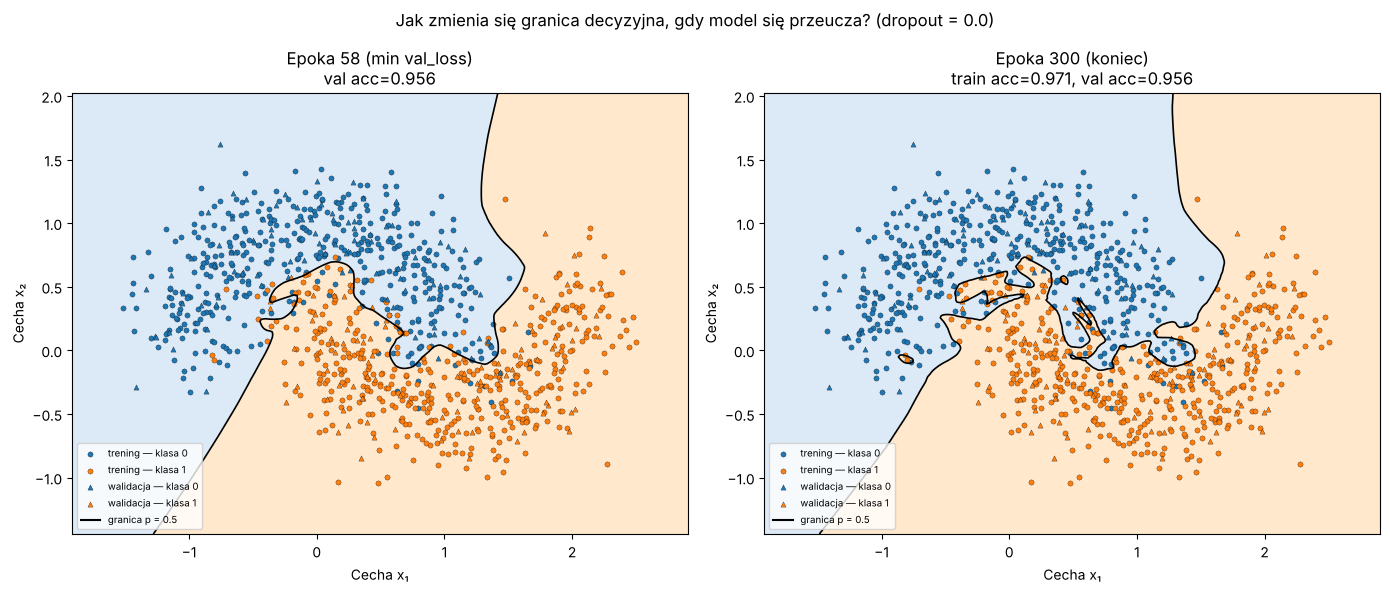

In [9]:
# granice decyzyjne: najlepsza epoka vs koniec treningu (stan przeuczony)
over_final = build_mlp(0.0, TRAIN_SEEDS[0])
over_final.set_weights(over["final_weights"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_boundary(axes[0], lambda G: over["model"].predict(G, batch_size=4096, verbose=0),
              f"Epoka {over['best_epoch']} (min val_loss)\nval acc={over['val_acc']:.3f}")
plot_boundary(axes[1], lambda G: over_final.predict(G, batch_size=4096, verbose=0),
              f"Epoka {EPOCHS_LONG} (koniec)\ntrain acc={over['final_train_acc']:.3f}, "
              f"val acc={over['final_val_acc']:.3f}")
fig.suptitle("Jak zmienia się granica decyzyjna, gdy model się przeucza? (dropout = 0.0)")
plt.tight_layout()
plt.show()

### 3b. Dodatkowo: niestabilny trening (zbyt duży learning rate)

Ten sam MLP i to samo ziarno (60 epok), zmieniony **tylko** learning rate: `0.003` (bazowy) vs `0.2`. Za duży krok Adama powoduje skoki straty między epokami (oscylacje / rozbieganie się) albo „martwe” neurony ReLU i utknięcie przy stracie ≈ ln 2 ≈ 0.693 (model przewiduje stałe 0.5). **Sposób ograniczenia:** mniejszy learning rate (lub harmonogram LR / `ReduceLROnPlateau`).

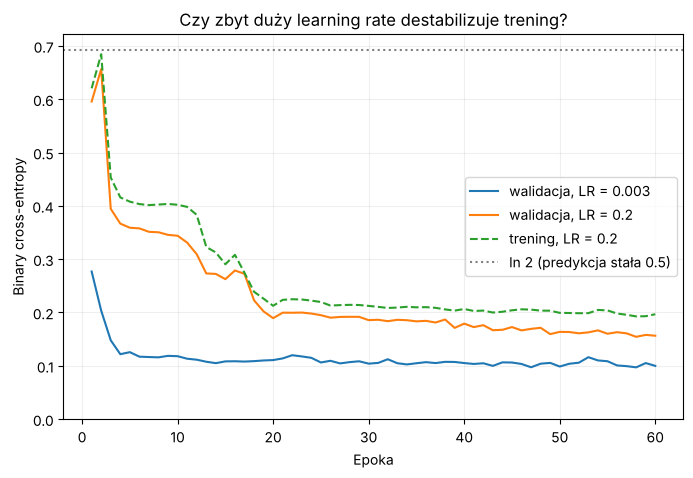

LR=0.003: min val BCE=0.097, średni skok val BCE między epokami=0.006, max skok=0.073, val acc (najlepsza epoka)=0.956
LR=0.2: min val BCE=0.154, średni skok val BCE między epokami=0.012, max skok=0.262, val acc (najlepsza epoka)=0.933


In [10]:
base = train_run(0.0, TRAIN_SEEDS[0])  # 60 epok, LR bazowy (też część eksperymentu dropout)
unstable = train_run(0.0, TRAIN_SEEDS[0], learning_rate=0.2)
ep = np.arange(1, EPOCHS + 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ep, base["val_loss"], label="walidacja, LR = 0.003")
ax.plot(ep, unstable["val_loss"], label="walidacja, LR = 0.2")
ax.plot(ep, unstable["train_loss_eval"], ls="--", label="trening, LR = 0.2")
ax.axhline(np.log(2), color="gray", ls=":", label="ln 2 (predykcja stała 0.5)")
ax.set(xlabel="Epoka", ylabel="Binary cross-entropy",
       title="Czy zbyt duży learning rate destabilizuje trening?")
ax.set_ylim(0, min(3, max(max(unstable["val_loss"]), max(base["val_loss"])) * 1.1))
ax.grid(alpha=0.2)
ax.legend()
plt.show()

for name, r in [("LR=0.003", base), ("LR=0.2", unstable)]:
    jumps = np.abs(np.diff(r["val_loss"]))
    print(f"{name}: min val BCE={min(r['val_loss']):.3f}, średni skok val BCE między epokami={jumps.mean():.3f}, "
          f"max skok={jumps.max():.3f}, val acc (najlepsza epoka)={r['val_acc']:.3f}")

## 4. Kontrolowany eksperyment: dropout `0.0 / 0.2 / 0.4`

**Zmieniamy tylko** prawdopodobieństwo dropoutu (po każdej warstwie ukrytej). **Stałe:** dane i podział, scaler, architektura, Adam (LR 0.003), batch 32, 60 epok, reguła wyboru epoki. Każda konfiguracja × 3 ziarna `[0, 1, 2]` = 9 treningów.

**Hipoteza:** dropout zmniejszy lukę między stratą treningową i walidacyjną oraz obniży walidacyjną stratę na końcu treningu; zbyt silny dropout może jednak zacząć powodować niedouczenie.

**Reguła wyboru (ustalona przed testem):** wybieramy dropout o najwyższym **średnim F1 na walidacji** (wagi z epoki min. `val_loss`); jeśli różnica do drugiego miejsca < 0.005, rozstrzyga niższa średnia minimalna `val_loss`.

In [11]:
DROPOUTS = [0.0, 0.2, 0.4]
records = []
for d in DROPOUTS:
    for s in TRAIN_SEEDS:
        r = train_run(d, s)
        records.append({
            "dropout": d, "seed": s, "best_epoch": r["best_epoch"],
            "min val BCE": min(r["val_loss"]),
            "final train BCE": r["train_loss_eval"][-1], "final val BCE": r["val_loss"][-1],
            "final gap (val-train)": r["gap_end"], "gap growth": r["gap_growth"],
            "val acc": r["val_acc"], "val F1": r["val_f1"],
        })
        print(f"dropout={d:.1f} seed={s}: val acc={r['val_acc']:.3f}, val F1={r['val_f1']:.3f}, "
              f"najlepsza epoka={r['best_epoch']}")

results = pd.DataFrame(records)
results.round(4)

dropout=0.0 seed=0: val acc=0.956, val F1=0.956, najlepsza epoka=58


dropout=0.0 seed=1: val acc=0.956, val F1=0.956, najlepsza epoka=49


dropout=0.0 seed=2: val acc=0.961, val F1=0.962, najlepsza epoka=41


dropout=0.2 seed=0: val acc=0.939, val F1=0.939, najlepsza epoka=39


dropout=0.2 seed=1: val acc=0.961, val F1=0.961, najlepsza epoka=26


dropout=0.2 seed=2: val acc=0.961, val F1=0.961, najlepsza epoka=60


dropout=0.4 seed=0: val acc=0.956, val F1=0.956, najlepsza epoka=34


dropout=0.4 seed=1: val acc=0.933, val F1=0.933, najlepsza epoka=52


dropout=0.4 seed=2: val acc=0.939, val F1=0.939, najlepsza epoka=50


,dropout,seed,best_epoch,min val BCE,final train BCE,final val BCE,final gap (val-train),gap growth,val acc,val F1
0,0.0,0,58,0.0971,0.1348,0.0999,-0.0349,0.0038,0.9556,0.9556
1,0.0,1,49,0.1001,0.1405,0.1047,-0.0359,0.0071,0.9556,0.9556
2,0.0,2,41,0.0942,0.1478,0.1062,-0.0416,0.0087,0.9611,0.9617
3,0.2,0,39,0.0997,0.1493,0.1148,-0.0345,0.0175,0.9389,0.9385
4,0.2,1,26,0.1037,0.1593,0.1130,-0.0463,0.0052,0.9611,0.9609
5,0.2,2,60,0.0960,0.1460,0.0960,-0.0500,0.0000,0.9611,0.9613
6,0.4,0,34,0.0992,0.1574,0.1171,-0.0403,0.0206,0.9556,0.9556
7,0.4,1,52,0.1011,0.1590,0.1074,-0.0516,0.0041,0.9333,0.9333
8,0.4,2,50,0.1016,0.1584,0.1096,-0.0487,0.0079,0.9389,0.9385


In [12]:
summary = results.drop(columns="seed").groupby("dropout").agg(["mean", "std"])
summary.round(4)

best_epoch          min val BCE         final train BCE          \
              mean      std        mean     std            mean     std   
dropout                                                                   
0.0        49.3333   8.5049      0.0971  0.0029          0.1410  0.0065   
0.2        41.6667  17.1561      0.0998  0.0038          0.1515  0.0069   
0.4        45.3333   9.8658      0.1006  0.0013          0.1583  0.0008   

        final val BCE         final gap (val-train)         gap growth  \
                 mean     std                  mean     std       mean   
dropout                                                                  
0.0            0.1036  0.0033               -0.0374  0.0036     0.0065   
0.2            0.1079  0.0104               -0.0436  0.0081     0.0076   
0.4            0.1114  0.0051               -0.0469  0.0058     0.0109   

                val acc          val F1          
            std    mean     std    mean     std  
dropout                                          
0.0      0.0025  0.9574  0.0032  0.9576  0.0036  
0.2      0.0090  0.9537  0.0128  0.9536  0.0130  
0.4      0.0086  0.9426  0.0116  0.9425  0.0116

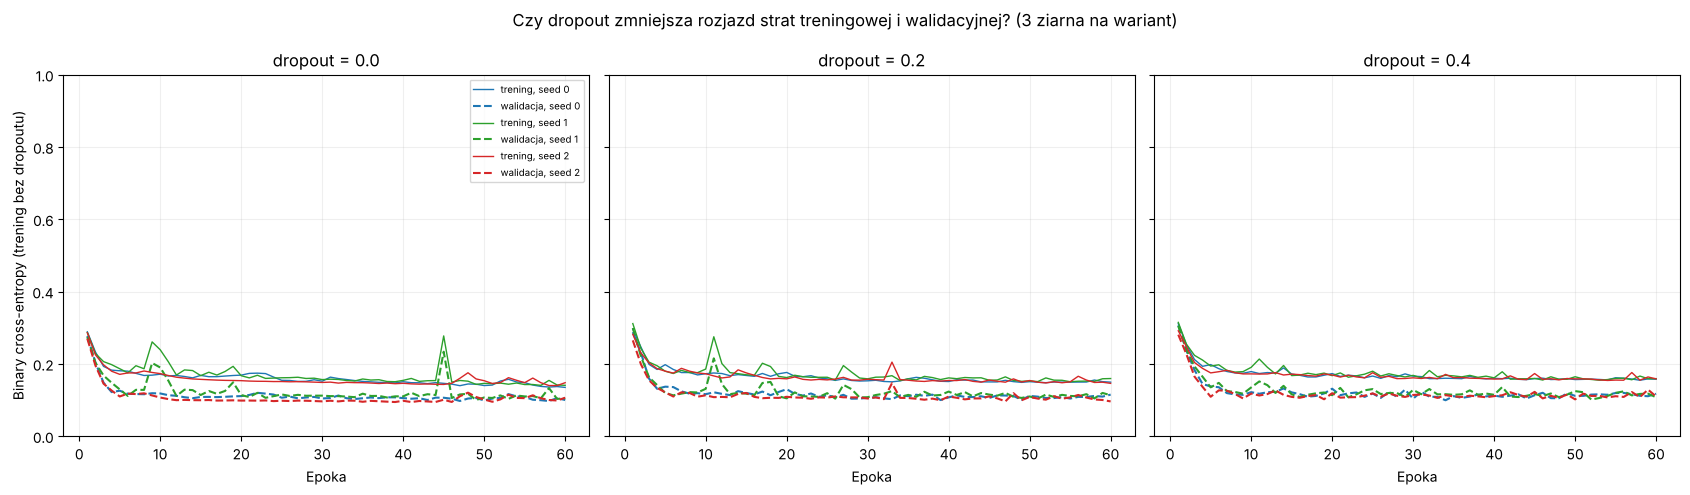

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
colors = ["tab:blue", "tab:green", "tab:red"]
for ax, d in zip(axes, DROPOUTS):
    for s, c in zip(TRAIN_SEEDS, colors):
        r = RUNS[(d, s, LEARNING_RATE, EPOCHS)]
        ax.plot(ep, r["train_loss_eval"], color=c, lw=1, label=f"trening, seed {s}")
        ax.plot(ep, r["val_loss"], color=c, lw=1.5, ls="--", label=f"walidacja, seed {s}")
    ax.set(xlabel="Epoka", title=f"dropout = {d}")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Binary cross-entropy (trening bez dropoutu)")
axes[0].set_ylim(0, 1.0)
axes[0].legend(fontsize=7)
fig.suptitle("Czy dropout zmniejsza rozjazd strat treningowej i walidacyjnej? (3 ziarna na wariant)")
plt.tight_layout()
plt.show()

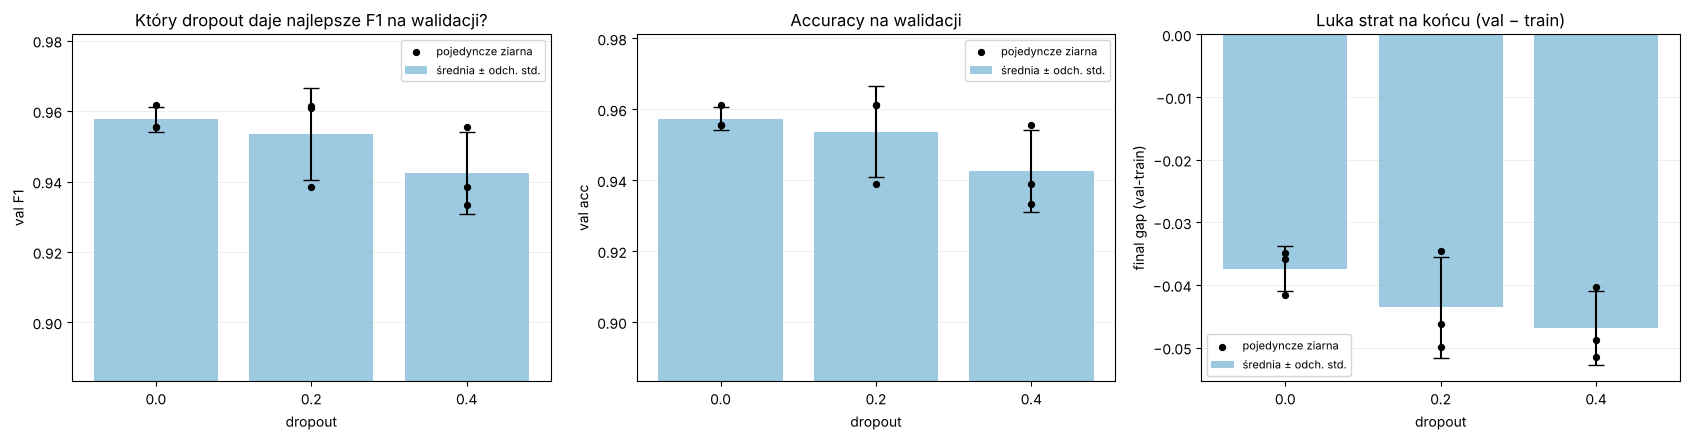

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title in [
    (axes[0], "val F1", "Który dropout daje najlepsze F1 na walidacji?"),
    (axes[1], "val acc", "Accuracy na walidacji"),
    (axes[2], "final gap (val-train)", "Luka strat na końcu (val − train)"),
]:
    m = results.groupby("dropout")[col].mean()
    sd = results.groupby("dropout")[col].std()
    xs = np.arange(len(DROPOUTS))
    ax.bar(xs, m.values, yerr=sd.values, capsize=6, color="#9ecae1", label="średnia ± odch. std.")
    for i, d in enumerate(DROPOUTS):
        vals = results.loc[results["dropout"] == d, col].values
        ax.scatter(np.full(len(vals), i), vals, color="k", zorder=3, s=18,
                   label="pojedyncze ziarna" if i == 0 else None)
    ax.set_xticks(xs, [str(d) for d in DROPOUTS])
    ax.set(xlabel="dropout", ylabel=col, title=title)
    if col != "final gap (val-train)":
        lo = results[col].min()
        ax.set_ylim(max(0, lo - 0.05), min(1.0, results[col].max() + 0.02))
    ax.grid(alpha=0.2, axis="y")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

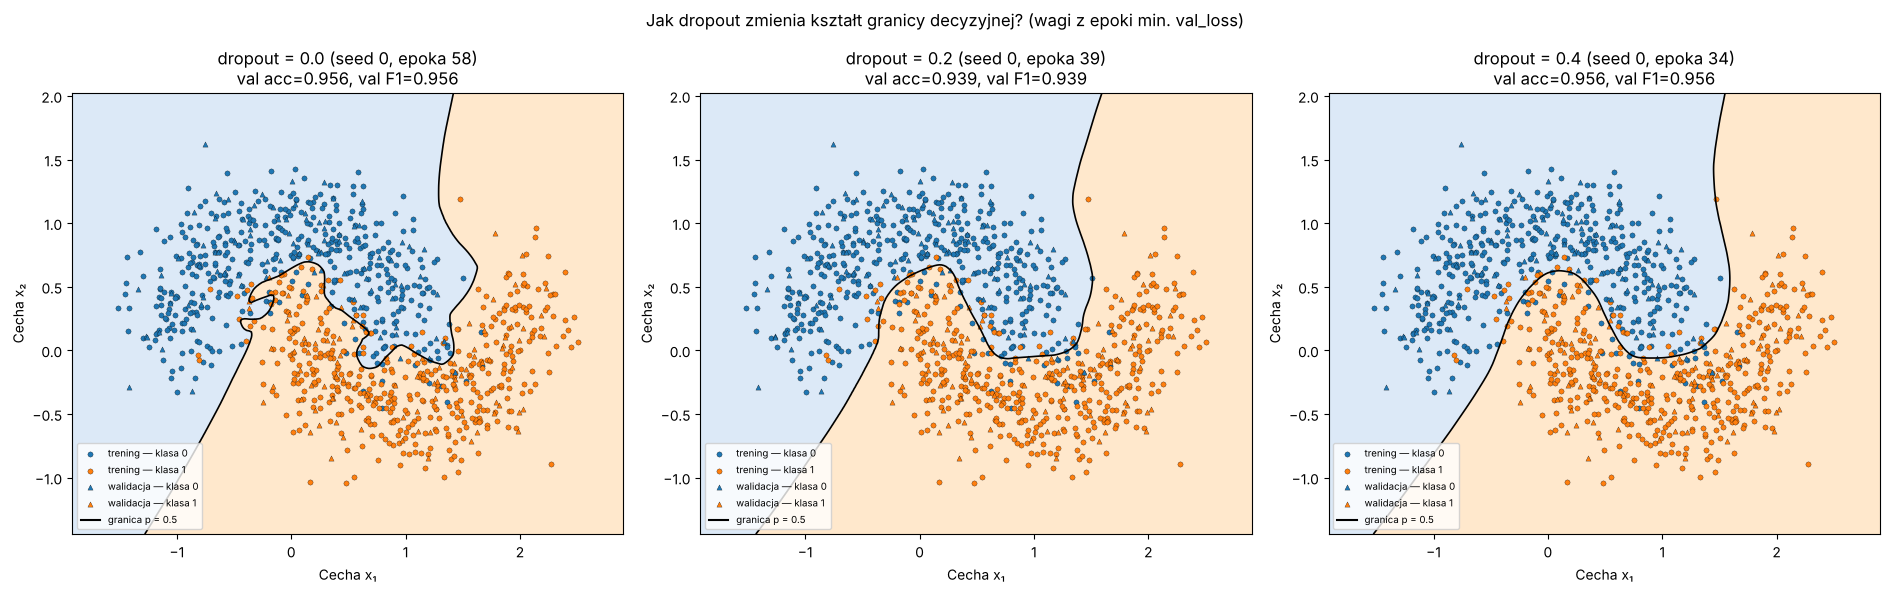

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, d in zip(axes, DROPOUTS):
    r = RUNS[(d, TRAIN_SEEDS[0], LEARNING_RATE, EPOCHS)]
    plot_boundary(ax, lambda G, m=r["model"]: m.predict(G, batch_size=4096, verbose=0),
                  f"dropout = {d} (seed {TRAIN_SEEDS[0]}, epoka {r['best_epoch']})\n"
                  f"val acc={r['val_acc']:.3f}, val F1={r['val_f1']:.3f}")
fig.suptitle("Jak dropout zmienia kształt granicy decyzyjnej? (wagi z epoki min. val_loss)")
plt.tight_layout()
plt.show()

### 4b. Uzupełnienie: dropout w długim treningu (300 epok, seed 0)

W 60 epokach model bez dropoutu dopiero zbliża się do przeuczenia, więc porównanie 60-epokowe słabo pokazuje *ograniczanie* przeuczenia. Dlatego dodatkowo (poza głównym porównaniem i **bez wpływu na wybór konfiguracji**) trenujemy warianty 0.2 i 0.4 tak samo długo jak model z diagnozy (300 epok, to samo ziarno) i porównujemy wzrost straty walidacyjnej oraz luki.

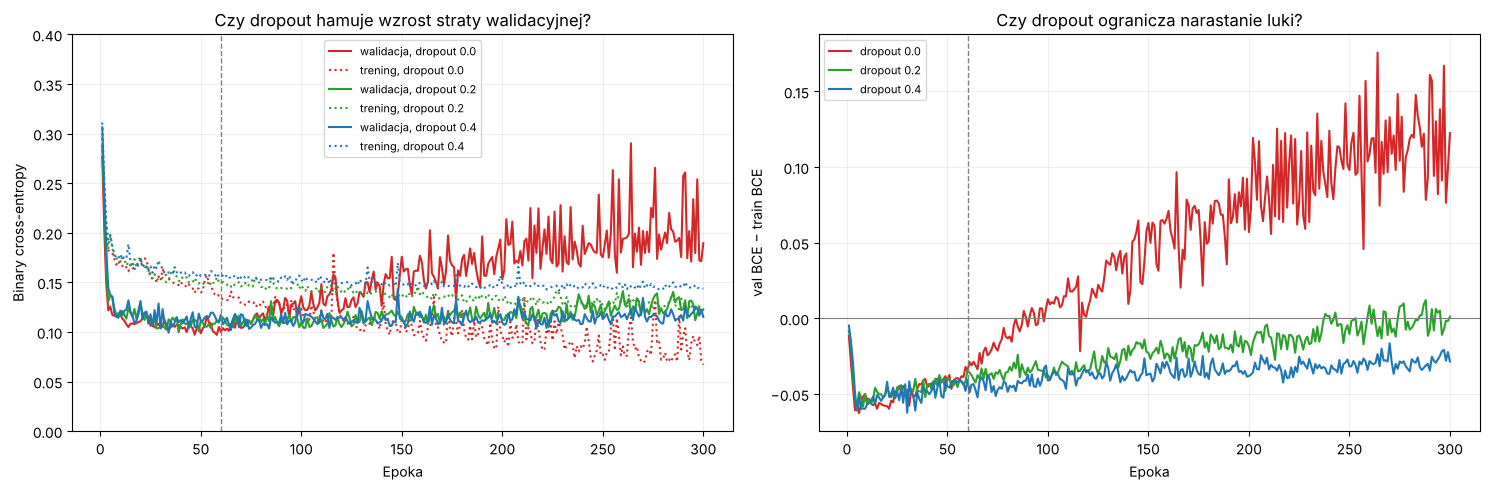

,best_epoch,min val BCE,val BCE @300,train BCE @300,gap growth,val acc (best ep.),val acc @300
dropout,,,,,,,
0.0,58,0.0971,0.1895,0.0670,0.1612,0.9556,0.9556
0.2,39,0.0997,0.1228,0.1216,0.0533,0.9389,0.9444
0.4,34,0.0992,0.1151,0.1436,0.0324,0.9556,0.9500


In [16]:
long_runs = {d: train_run(d, TRAIN_SEEDS[0], epochs=EPOCHS_LONG) for d in DROPOUTS}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for d, c in zip(DROPOUTS, ["tab:red", "tab:green", "tab:blue"]):
    r = long_runs[d]
    axes[0].plot(ep_long, r["val_loss"], color=c, label=f"walidacja, dropout {d}")
    axes[0].plot(ep_long, r["train_loss_eval"], color=c, ls=":", label=f"trening, dropout {d}")
    axes[1].plot(ep_long, np.array(r["val_loss"]) - np.array(r["train_loss_eval"]), color=c, label=f"dropout {d}")
axes[0].set(xlabel="Epoka", ylabel="Binary cross-entropy", title="Czy dropout hamuje wzrost straty walidacyjnej?")
axes[0].set_ylim(0, max(0.4, max(long_runs[0.0]["val_loss"]) * 1.05))
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set(xlabel="Epoka", ylabel="val BCE − train BCE", title="Czy dropout ogranicza narastanie luki?")
for ax in axes:
    ax.axvline(EPOCHS, color="gray", ls="--", lw=1)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

long_df = pd.DataFrame([{
    "dropout": d, "best_epoch": r["best_epoch"], "min val BCE": min(r["val_loss"]),
    "val BCE @300": r["val_loss"][-1], "train BCE @300": r["train_loss_eval"][-1],
    "gap growth": r["gap_growth"], "val acc (best ep.)": r["val_acc"], "val acc @300": r["final_val_acc"],
} for d, r in long_runs.items()]).set_index("dropout")
long_df.round(4)

### Odpowiedzi na pytania do analizy (liczone z wyników powyżej)

In [17]:
g = results.groupby("dropout")
gap_m, gap_s = g["final gap (val-train)"].mean(), g["final gap (val-train)"].std()
growth_m = g["gap growth"].mean()
f1_m, f1_s = g["val F1"].mean(), g["val F1"].std()
acc_m = g["val acc"].mean()
minval_m = g["min val BCE"].mean()
long_growth = long_df["gap growth"]

print("1) Czy dropout zmienił różnicę między stratą treningową i walidacyjną?")
print("   60 epok (średnia z 3 ziaren):")
for d in DROPOUTS:
    print(f"     dropout={d}: luka końcowa = {gap_m[d]:+.3f} ± {gap_s[d]:.3f}, wzrost luki od najlepszej epoki = {growth_m[d]:+.3f}")
print("   300 epok (seed 0): wzrost luki od najlepszej epoki:",
      ", ".join(f"{d}: {long_growth[d]:+.3f}" for d in DROPOUTS))
DROPOUT_HELPS = bool(long_growth[0.2] < long_growth[0.0] and long_growth[0.4] < long_growth[0.0])
print("   → W długim treningu dropout", "OGRANICZA" if DROPOUT_HELPS else "NIE ogranicza wyraźnie",
      "narastanie luki (przeuczenie). W 60 epokach przeuczenie dopiero się zaczyna, więc różnice luki są małe "
      "w porównaniu z rozrzutem między ziarnami.")

print("\n2) Która wartość daje najlepszy wynik walidacyjny i czy przewaga jest powtarzalna?")
for d in DROPOUTS:
    print(f"   dropout={d}: val F1 = {f1_m[d]:.4f} ± {f1_s[d]:.4f}, val acc = {acc_m[d]:.4f}")
ranked = f1_m.sort_values(ascending=False)
best_d, second_d = ranked.index[0], ranked.index[1]
diff = ranked.iloc[0] - ranked.iloc[1]
f1_by_seed = results.pivot(index="seed", columns="dropout", values="val F1")
wins = int((f1_by_seed[best_d] >= f1_by_seed[second_d]).sum())
print(f"   → najwyższe średnie F1: dropout={best_d} (przewaga nad {second_d}: {diff:+.4f}; "
      f"lepszy lub równy w {wins}/3 ziarnach). "
      + ("Przewaga mniejsza niż odchylenie std. — NIE jest wyraźnie powtarzalna."
         if diff < max(f1_s[best_d], f1_s[second_d]) else "Przewaga większa niż rozrzut — powtarzalna."))

print("\n3) Czy mocniejsza regularyzacja zawsze poprawia wynik?")
print(f"   val F1: 0.0 → {f1_m[0.0]:.4f}, 0.2 → {f1_m[0.2]:.4f}, 0.4 → {f1_m[0.4]:.4f}")
print("   → " + ("NIE — wynik nie rośnie monotonicznie z dropoutem." if not (f1_m[0.4] > f1_m[0.2] > f1_m[0.0])
              else "W tym zakresie tak, ale to nie musi trwać przy większych wartościach."))
tr_m = g["final train BCE"].mean()
print(f"   Końcowa strata treningowa (bez dropoutu): " + ", ".join(f"{d}: {tr_m[d]:.3f}" for d in DROPOUTS))
print("   Niedouczenie od zbyt silnej regularyzacji: strata treningowa zostaje wyższa i bliska walidacyjnej, "
      "granica jest wygładzona, accuracy spada na OBU zbiorach.")

print("\n4) Czy wnioski są podobne przy różnych ziarnach?")
print("   Rozrzut (std) val F1:", ", ".join(f"{d}: {f1_s[d]:.4f}" for d in DROPOUTS))
print("   Rozrzut luki strat:", ", ".join(f"{d}: {gap_s[d]:.4f}" for d in DROPOUTS))
print("   Różnice średnich F1 między wariantami porównujemy z tymi rozrzutami (pkt 2).")

1) Czy dropout zmienił różnicę między stratą treningową i walidacyjną?
   60 epok (średnia z 3 ziaren):
     dropout=0.0: luka końcowa = -0.037 ± 0.004, wzrost luki od najlepszej epoki = +0.007
     dropout=0.2: luka końcowa = -0.044 ± 0.008, wzrost luki od najlepszej epoki = +0.008
     dropout=0.4: luka końcowa = -0.047 ± 0.006, wzrost luki od najlepszej epoki = +0.011
   300 epok (seed 0): wzrost luki od najlepszej epoki: 0.0: +0.161, 0.2: +0.053, 0.4: +0.032
   → W długim treningu dropout OGRANICZA narastanie luki (przeuczenie). W 60 epokach przeuczenie dopiero się zaczyna, więc różnice luki są małe w porównaniu z rozrzutem między ziarnami.

2) Która wartość daje najlepszy wynik walidacyjny i czy przewaga jest powtarzalna?
   dropout=0.0: val F1 = 0.9576 ± 0.0036, val acc = 0.9574
   dropout=0.2: val F1 = 0.9536 ± 0.0130, val acc = 0.9537
   dropout=0.4: val F1 = 0.9425 ± 0.0116, val acc = 0.9426
   → najwyższe średnie F1: dropout=0.0 (przewaga nad 0.2: +0.0040; lepszy lub równy w 

## 5. Wybór konfiguracji (tylko walidacja — przed testem)

Stosujemy regułę zapisaną w sekcji 4. Wybór jest drukowany i zamrażany **zanim** dotkniemy zbioru testowego.

In [18]:
cand = f1_m.sort_values(ascending=False)
CHOSEN_DROPOUT = cand.index[0]
if cand.iloc[0] - cand.iloc[1] < 0.005:  # remis → niższa średnia min. val_loss
    tied = cand[cand >= cand.iloc[0] - 0.005].index
    CHOSEN_DROPOUT = minval_m.loc[tied].idxmin()
    reason = f"remis F1 (<0.005) → rozstrzyga niższa średnia min. val BCE ({minval_m[CHOSEN_DROPOUT]:.4f})"
else:
    reason = f"najwyższe średnie val F1 = {f1_m[CHOSEN_DROPOUT]:.4f}"
print(f"WYBRANA KONFIGURACJA: dropout = {CHOSEN_DROPOUT}  ({reason})")
print("Model końcowy: 3 modele tej konfiguracji (ziarna 0,1,2), każdy z wagami z epoki o min. val_loss.")

WYBRANA KONFIGURACJA: dropout = 0.0  (remis F1 (<0.005) → rozstrzyga niższa średnia min. val BCE (0.0971))
Model końcowy: 3 modele tej konfiguracji (ziarna 0,1,2), każdy z wagami z epoki o min. val_loss.


## 6. Test końcowy (jednokrotnie)

Zbiór testowy przekształcamy **tym samym** scalerem (dopasowanym na treningu). Oceniamy 3 modele wybranej konfiguracji i raportujemy średnią ± odchylenie. Po tej komórce modelu już nie zmieniamy.

In [19]:
X_test_s = scaler.transform(X_test).astype("float32")  # ten sam scaler; bez ponownego dopasowania

test_rows = []
for s in TRAIN_SEEDS:
    r = RUNS[(CHOSEN_DROPOUT, s, LEARNING_RATE, EPOCHS)]
    st = scores(y_test, r["model"].predict(X_test_s, verbose=0))
    test_rows.append({"seed": s, "val acc": r["val_acc"], "val F1": r["val_f1"],
                      "test acc": st["accuracy"], "test F1": st["f1"]})
test_df = pd.DataFrame(test_rows).set_index("seed")
test_df.loc["średnia"] = test_df.mean()
test_df.loc["odch. std."] = test_df.iloc[:3].std()
display(test_df.round(4))

t_acc, t_f1 = test_df.loc["średnia", "test acc"], test_df.loc["średnia", "test F1"]
v_acc, v_f1 = test_df.loc["średnia", "val acc"], test_df.loc["średnia", "val F1"]
print(f"Test (dropout={CHOSEN_DROPOUT}): accuracy = {t_acc:.4f}, F1 = {t_f1:.4f}")
print(f"Różnica test − walidacja: acc {t_acc - v_acc:+.4f}, F1 {t_f1 - v_f1:+.4f}")
print("Zbiór testowy ma 180 przykładów → 1 błąd ≈ 0.56 pp accuracy; różnice rzędu kilku błędów mieszczą się "
      "w losowości próby. Walidacja była użyta do wyboru epoki i dropoutu, więc lekko niższy wynik testowy jest oczekiwany.")

,val acc,val F1,test acc,test F1
seed,,,,
0,0.9556,0.9556,0.9389,0.9371
1,0.9556,0.9556,0.9500,0.9486
2,0.9611,0.9617,0.9444,0.9438
średnia,0.9574,0.9576,0.9444,0.9432
odch. std.,0.0032,0.0036,0.0056,0.0057


Test (dropout=0.0): accuracy = 0.9444, F1 = 0.9432
Różnica test − walidacja: acc -0.0130, F1 -0.0144
Zbiór testowy ma 180 przykładów → 1 błąd ≈ 0.56 pp accuracy; różnice rzędu kilku błędów mieszczą się w losowości próby. Walidacja była użyta do wyboru epoki i dropoutu, więc lekko niższy wynik testowy jest oczekiwany.


## 7. Raport końcowy

**Pytanie badawcze i hipoteza.** Czy dropout ogranicza przeuczenie MLP na danych „dwa półksiężyce” (1200 pkt, szum 0.25)? Hipoteza: dropout zmniejszy lukę między stratą treningową a walidacyjną i nie pogorszy (lub poprawi) F1 na walidacji; zbyt duży dropout może jednak prowadzić do niedouczenia.

**Metoda.** `make_moons(1200, noise=0.25, random_state=42)`; stratyfikowany podział 70/15/15 (`random_state=42`); `StandardScaler` dopasowany tylko na treningu. Baseline’y: klasa większościowa, regresja logistyczna. MLP: 3 × Dense(256, ReLU) + Dropout(p) → Dense(1, sigmoid), BCE, Adam (LR 0.003), batch 32, 60 epok (diagnoza przeuczenia i uzupełnienie 4b: 300 epok). Ziarna treningu `[0, 1, 2]` ustawiane przez `keras.utils.set_random_seed` + deterministyczne operacje TF. Epoka wybierana jako minimum `val_loss`.

**Diagnoza.**
- *Niedouczenie* — regresja logistyczna: podobne (słabe) wyniki na treningu i walidacji, prosta granica decyzyjna nie oddaje kształtu danych.
- *Przeuczenie* — MLP bez dropoutu trenowany 300 epok: strata treningowa spada do końca, a walidacyjna po minimum (ok. 60. epoki) rośnie; luka val − train rośnie, granica decyzyjna „zawija się” wokół pojedynczych zaszumionych punktów. Ponieważ ten zbiór walidacyjny jest nieco łatwiejszy (val BCE < train BCE nawet dla regresji logistycznej), diagnozę opieramy na **wzroście** luki, nie na jej znaku.
- *Niestabilny trening* — LR = 0.2: duże skoki straty między epokami; ograniczenie: mniejszy LR.

**Eksperyment.** Zmieniany tylko dropout (0.0 / 0.2 / 0.4); reszta stała. Każdy wariant × 3 ziarna, wyniki jako średnia ± odchylenie std.

**Wyniki i wnioski** — liczby z tego uruchomienia (komórka niżej). Wnioski opierają się na: (1) luce końcowej strat val − train, (2) średnim F1/accuracy na walidacji i ich rozrzucie między ziarnami, (3) jednokrotnym wyniku testowym.

**Ograniczenia.** W limicie 60 epok przeuczenie dopiero się zaczyna, więc główne porównanie dropout ma małą moc — efekt dropoutu lepiej widać w długim treningu (4b, jedno ziarno). Tylko 3 ziarna — niepewność średnich jest duża; mały zbiór walidacyjny/testowy (180 pkt) → pojedyncze błędy przesuwają accuracy o ~0.56 pp; jeden zbiór danych 2D z ustalonym szumem (Bayesowski błąd jest niezerowy, więc wysoka accuracy ma górny limit); zbadano jeden czynnik (dropout) przy jednej architekturze i LR; wybór epoki na walidacji lekko „zużywa” walidację.

In [20]:
print("=== PODSUMOWANIE LICZBOWE ===")
print(f"Baseline naiwny (val): acc={baseline_df.iloc[0]['val acc']:.3f}, F1={baseline_df.iloc[0]['val F1']:.3f}")
print(f"Regresja logistyczna (val): acc={baseline_df.iloc[1]['val acc']:.3f}, F1={baseline_df.iloc[1]['val F1']:.3f}")
print(f"MLP bez dropoutu, seed 0, {EPOCHS_LONG} epok: min val BCE={min(over['val_loss']):.3f} (epoka {over['best_epoch']}) "
      f"→ końcowa {over['val_loss'][-1]:.3f}; końcowa train BCE={over['train_loss_eval'][-1]:.3f}; "
      f"wzrost luki {over['gap_growth']:+.3f}")
print("\nWalidacja (średnia ± std z 3 ziaren):")
for d in DROPOUTS:
    print(f"  dropout={d}: val acc={acc_m[d]:.4f}, val F1={f1_m[d]:.4f} ± {f1_s[d]:.4f}, "
          f"luka strat={gap_m[d]:+.3f} ± {gap_s[d]:.3f}")
print(f"\nWybrany dropout = {CHOSEN_DROPOUT} → TEST: acc={t_acc:.4f}, F1={t_f1:.4f}")
print(f"\n{EPOCHS_LONG} epok, wzrost luki od najlepszej epoki: " + ", ".join(f"dropout {d}: {long_growth[d]:+.3f}" for d in DROPOUTS))
print("Hipoteza (dropout ogranicza przeuczenie):",
      "WSPARTA w długim treningu (mniejszy wzrost luki z dropoutem)." if DROPOUT_HELPS else "NIE wsparta przez wyniki.")
print("Hipoteza (dropout poprawia val F1 w 60 epokach):",
      "WSPARTA." if max(f1_m[0.2], f1_m[0.4]) - f1_m[0.0] > f1_s.max() else
      "NIE wsparta — różnice F1 mieszczą się w rozrzucie między ziarnami.")

=== PODSUMOWANIE LICZBOWE ===
Baseline naiwny (val): acc=0.500, F1=0.000
Regresja logistyczna (val): acc=0.872, F1=0.870
MLP bez dropoutu, seed 0, 300 epok: min val BCE=0.097 (epoka 58) → końcowa 0.190; końcowa train BCE=0.067; wzrost luki +0.161

Walidacja (średnia ± std z 3 ziaren):
  dropout=0.0: val acc=0.9574, val F1=0.9576 ± 0.0036, luka strat=-0.037 ± 0.004
  dropout=0.2: val acc=0.9537, val F1=0.9536 ± 0.0130, luka strat=-0.044 ± 0.008
  dropout=0.4: val acc=0.9426, val F1=0.9425 ± 0.0116, luka strat=-0.047 ± 0.006

Wybrany dropout = 0.0 → TEST: acc=0.9444, F1=0.9432

300 epok, wzrost luki od najlepszej epoki: dropout 0.0: +0.161, dropout 0.2: +0.053, dropout 0.4: +0.032
Hipoteza (dropout ogranicza przeuczenie): WSPARTA w długim treningu (mniejszy wzrost luki z dropoutem).
Hipoteza (dropout poprawia val F1 w 60 epokach): NIE wsparta — różnice F1 mieszczą się w rozrzucie między ziarnami.


## Checklista wymagań

- [x] 1200 przykładów, szum 0.25, ziarno danych 42.
- [x] Stratyfikowany podział 70/15/15; scaler dopasowany tylko na treningu.
- [x] Naiwny baseline i model liniowy ocenione na walidacji.
- [x] MLP: ≥ 2 warstwy ukryte (3 × 256), ReLU, sigmoid na wyjściu, BCE.
- [x] Pokazano niedouczenie, przeuczenie (oraz dodatkowo niestabilny trening).
- [x] Dodatkowo: dropout w długim treningu (300 epok) — bez wpływu na wybór konfiguracji.
- [x] Dropout 0.0 / 0.2 / 0.4 przy stałych pozostałych warunkach, 60 epok.
- [x] Każdy wariant × 3 ziarna, średnia i odchylenie std.
- [x] Krzywe strat, granice decyzyjne, accuracy/F1 z walidacji.
- [x] Test użyty jednokrotnie po wyborze konfiguracji.
- [x] Raport z wnioskami i ograniczeniami.

**Źródła:** materiały z zajęć (lab02, lab03 — Keras, podział danych, granice decyzyjne); dokumentacja scikit-learn i Keras.